In [1]:
from pathlib import Path

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

In [3]:
from ml_gearbox.audit import numeric_profile
from ml_gearbox.eda import (
    target_distribution, zero_percentage, iqr_outlier_summary,
    categorical_target_rate, numeric_target_rate_by_quantile,
    correlation_matrix, high_correlation_pairs,
    plot_numeric_distribution, plot_categorical_target_rate,
    plot_numeric_target_rate, plot_correlation_heatmap
)

Matplotlib is building the font cache; this may take a moment.


In [7]:
train = pd.read_parquet("../data/processed/train.parquet")
TARGET = "loan_status"

In [8]:
NUMERIC = ["person_age", "person_income", "person_emp_length", "loan_amnt", "loan_int_rate", "loan_percent_income", "cb_person_cred_hist_length"]
CATEGORICAL = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]
display(target_distribution(train, TARGET))

,count,percentage
loan_status,,
0,20378,78.184469
1,5686,21.815531


,count,mean,std,min,25%,50%,75%,max,median,skew,n_unique
person_income,26064.0,66043.498235,63715.995292,4000.00,38443.25,55000.00,79000.00,6000000.00,55000.00,36.061898,3709
person_emp_length,25326.0,4.794598,4.172469,0.00,2.00,4.00,7.00,123.00,4.00,2.915725,35
person_age,26064.0,27.702732,6.327287,20.00,23.00,26.00,30.00,144.00,26.00,2.737877,54
cb_person_cred_hist_length,26064.0,5.786641,4.034795,2.00,3.00,4.00,8.00,30.00,4.00,1.662461,29
loan_amnt,26064.0,9569.114487,6295.931312,500.00,5000.00,8000.00,12000.00,35000.00,8000.00,1.195170,712
loan_percent_income,26064.0,0.170179,0.106807,0.00,0.09,0.15,0.23,0.83,0.15,1.070277,76
loan_int_rate,23563.0,11.015630,3.235240,5.42,7.90,10.99,13.47,22.48,10.99,0.197493,338


,feature,zero_pct
0,person_emp_length,12.580571
1,loan_percent_income,0.026857


,feature,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_pct
0,loan_amnt,5000.00,12000.00,7000.00,-5500.000,22500.000,1371,5.260129
1,person_income,38443.25,79000.00,40556.75,-22391.875,139835.125,1285,4.930172
2,person_age,23.00,30.00,7.00,12.500,40.500,1145,4.393033
3,cb_person_cred_hist_length,3.00,8.00,5.00,-4.500,15.500,892,3.422345
4,person_emp_length,2.00,7.00,5.00,-5.500,14.500,699,2.681860
5,loan_percent_income,0.09,0.23,0.14,-0.120,0.440,531,2.037293
6,loan_int_rate,7.90,13.47,5.57,-0.455,21.825,3,0.011510


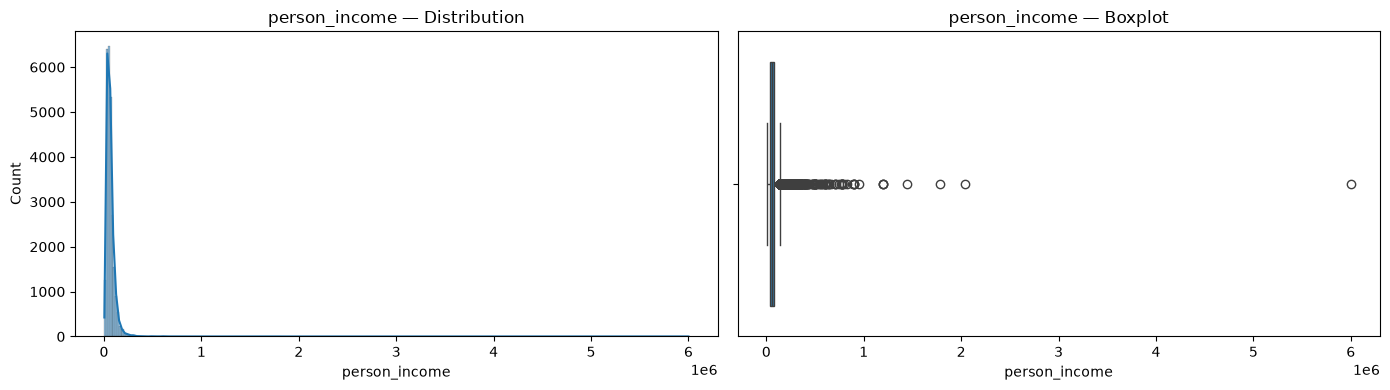

In [6]:
display(numeric_profile(train[NUMERIC]))
display(zero_percentage(train, NUMERIC))
display(iqr_outlier_summary(train, NUMERIC))
plot_numeric_distribution(train, "person_income")


 person_home_ownership


,person_home_ownership,count,positives,target_rate,target_rate_pct
0,OTHER,89,29,0.325843,32.584270
1,RENT,13198,4180,0.316715,31.671465
2,MORTGAGE,10687,1324,0.123889,12.388884
3,OWN,2090,153,0.073206,7.320574


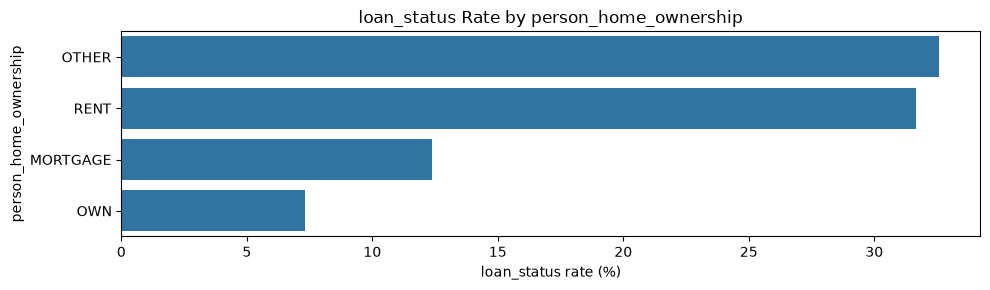


 loan_intent


,loan_intent,count,positives,target_rate,target_rate_pct
0,DEBTCONSOLIDATION,4165,1159,0.278271,27.827131
1,MEDICAL,4894,1312,0.268083,26.808337
2,HOMEIMPROVEMENT,2877,748,0.259993,25.999305
3,PERSONAL,4378,884,0.201919,20.191868
4,EDUCATION,5178,904,0.174585,17.458478
5,VENTURE,4572,679,0.148513,14.851269


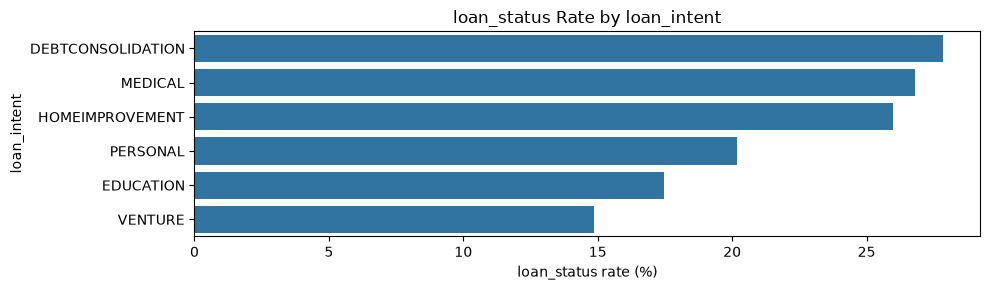


 loan_grade


,loan_grade,count,positives,target_rate,target_rate_pct
0,G,44,43,0.977273,97.727273
1,F,195,139,0.712821,71.282051
2,E,771,494,0.640726,64.072633
3,D,2875,1706,0.593391,59.339130
4,C,5232,1070,0.204511,20.451070
5,B,8326,1370,0.164545,16.454480
6,A,8621,864,0.100220,10.022039


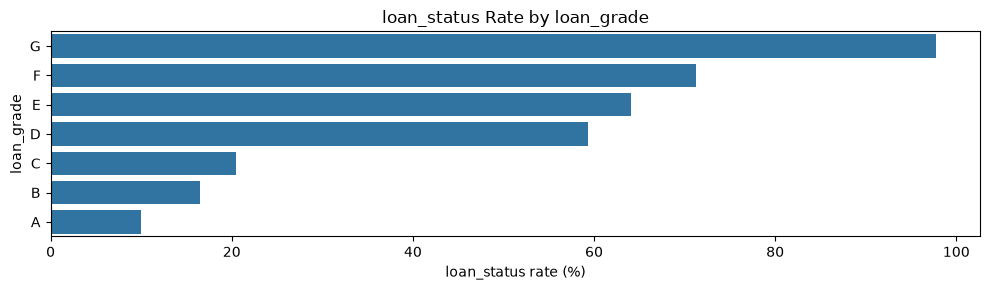


 cb_person_default_on_file


,cb_person_default_on_file,count,positives,target_rate,target_rate_pct
0,Y,4611,1738,0.376925,37.692475
1,N,21453,3948,0.184030,18.403021


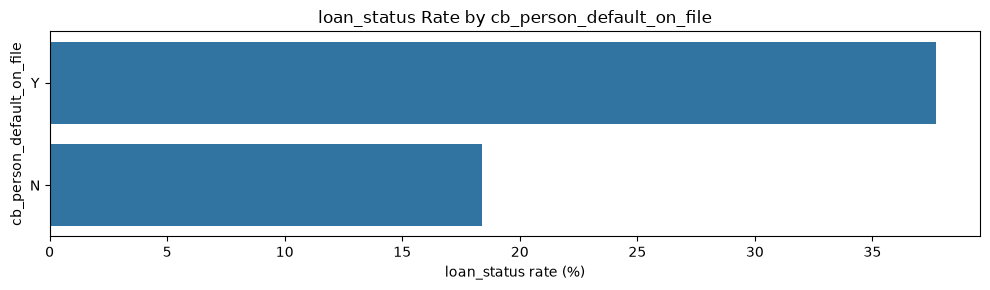

In [9]:
for feature in CATEGORICAL:
    print("\n", feature)
    display(categorical_target_rate(train, feature, TARGET))
    plot_categorical_target_rate(train, feature, TARGET)


 person_age


,bin,count,positives,target_rate,target_rate_pct
0,"(19.999, 22.0]",3912,1011,0.258436,25.843558
1,"(22.0, 23.0]",3125,675,0.216000,21.600000
2,"(23.0, 24.0]",2829,602,0.212796,21.279604
3,"(24.0, 25.0]",2451,544,0.221950,22.195022
4,"(25.0, 26.0]",1988,414,0.208249,20.824950
5,"(26.0, 27.0]",1700,360,0.211765,21.176471
6,"(27.0, 29.0]",2815,592,0.210302,21.030195
7,"(29.0, 32.0]",2751,549,0.199564,19.956379
8,"(32.0, 36.0]",2192,456,0.208029,20.802920
9,"(36.0, 144.0]",2301,483,0.209909,20.990874


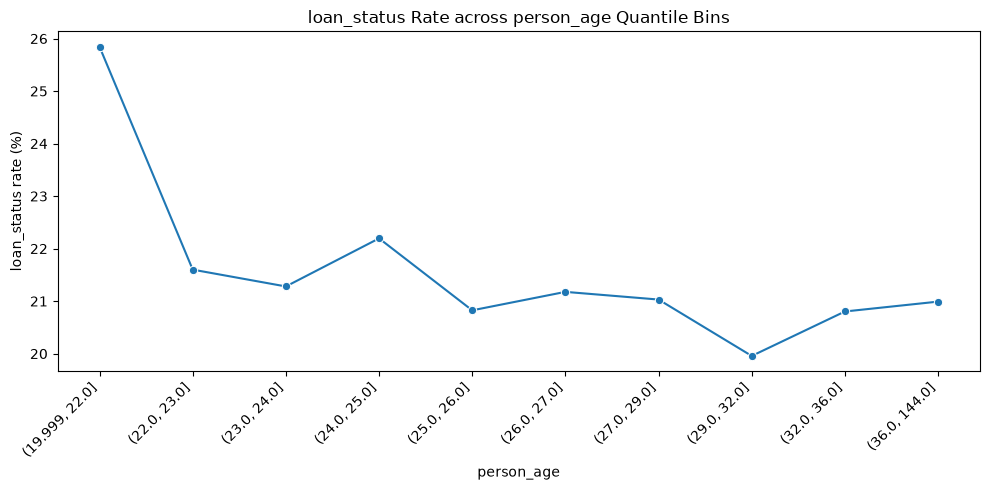


 person_income


,bin,count,positives,target_rate,target_rate_pct
0,"(3999.999, 28701.2]",2607,1231,0.472190,47.219026
1,"(28701.2, 35000.0]",2692,1064,0.395245,39.524517
2,"(35000.0, 42000.0]",2862,656,0.229210,22.921034
3,"(42000.0, 48996.0]",2272,511,0.224912,22.491197
4,"(48996.0, 55000.0]",2676,536,0.200299,20.029895
5,"(55000.0, 63000.0]",2574,460,0.178710,17.871018
6,"(63000.0, 73000.0]",2625,403,0.153524,15.352381
7,"(73000.0, 86000.0]",2597,358,0.137851,13.785137
8,"(86000.0, 110000.0]",2557,231,0.090340,9.034024
9,"(110000.0, 6000000.0]",2602,236,0.090699,9.069946


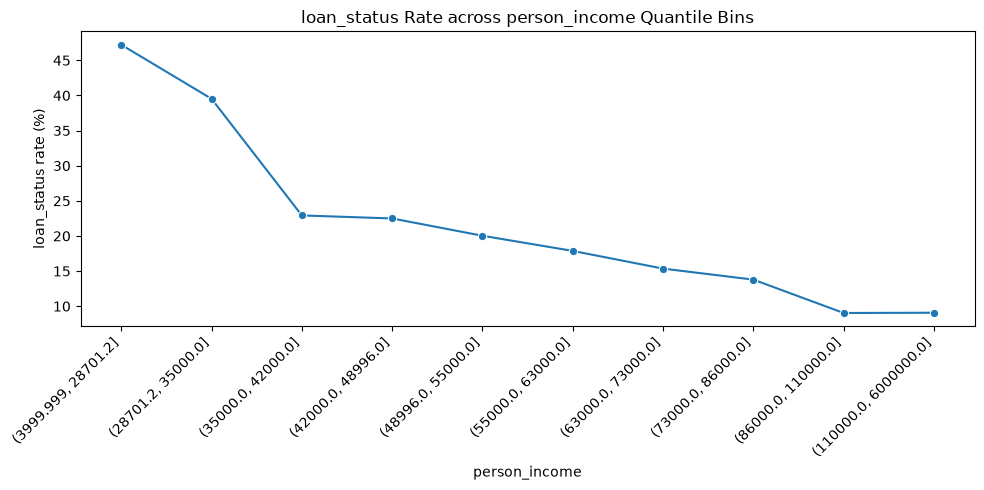


 loan_amnt


,bin,count,positives,target_rate,target_rate_pct
0,"(499.999, 3000.0]",3187,686,0.215249,21.524945
1,"(3000.0, 4400.0]",2031,414,0.203840,20.384047
2,"(4400.0, 5500.0]",2779,535,0.192515,19.251529
3,"(5500.0, 6800.0]",2464,379,0.153815,15.381494
4,"(6800.0, 8000.0]",3002,528,0.175883,17.588274
5,"(8000.0, 10000.0]",3785,726,0.191810,19.180978
6,"(10000.0, 12000.0]",2310,467,0.202165,20.216450
7,"(12000.0, 14500.0]",1354,346,0.255539,25.553914
8,"(14500.0, 19000.0]",2592,718,0.277006,27.700617
9,"(19000.0, 35000.0]",2560,887,0.346484,34.648438


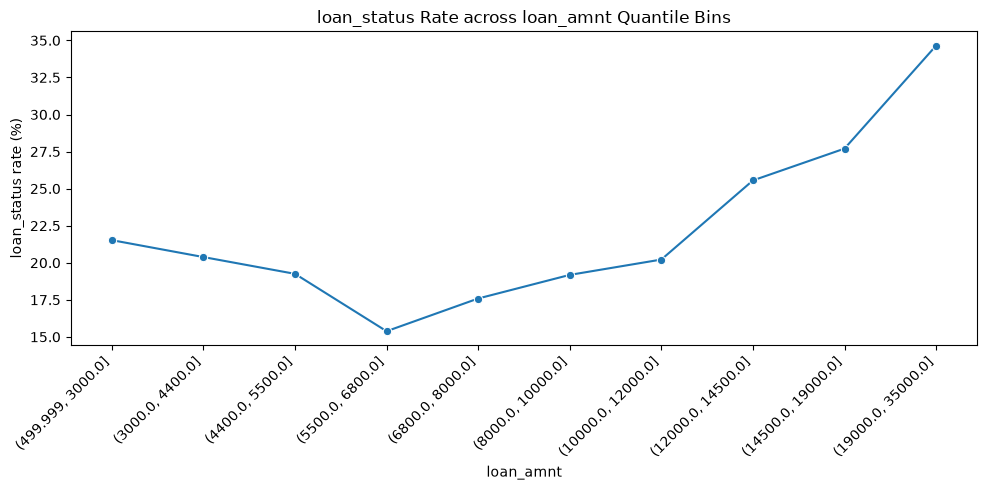


 loan_percent_income


,bin,count,positives,target_rate,target_rate_pct
0,"(-0.001, 0.05]",2775,278,0.100180,10.018018
1,"(0.05, 0.08]",3273,414,0.126489,12.648946
2,"(0.08, 0.1]",2329,297,0.127523,12.752254
3,"(0.1, 0.12]",2138,255,0.119270,11.927035
4,"(0.12, 0.15]",3214,416,0.129434,12.943373
5,"(0.15, 0.18]",2687,482,0.179382,17.938221
6,"(0.18, 0.21]",2333,442,0.189456,18.945564
7,"(0.21, 0.25]",2324,451,0.194062,19.406196
8,"(0.25, 0.32]",2507,894,0.356602,35.660152
9,"(0.32, 0.83]",2484,1757,0.707327,70.732689


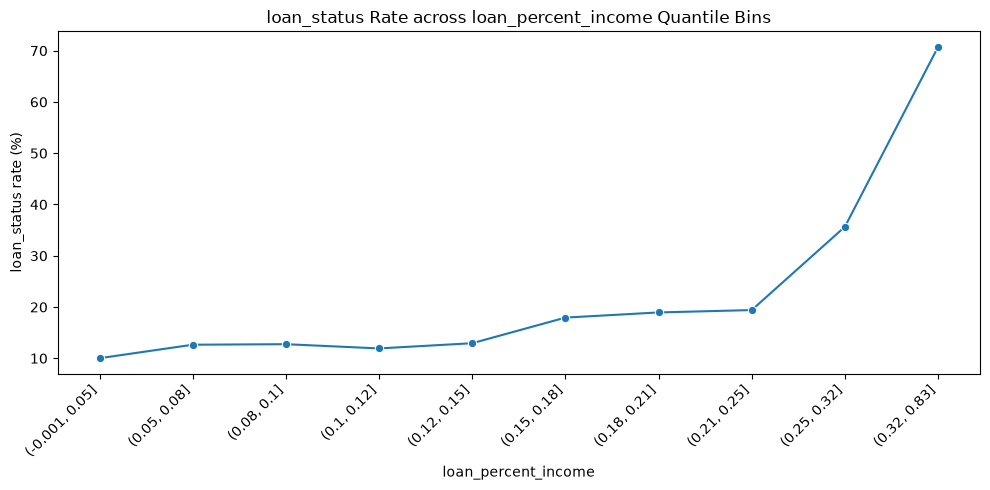


 cb_person_cred_hist_length


,bin,count,positives,target_rate,target_rate_pct
0,"(1.999, 3.0]",9535,2201,0.230834,23.083377
1,"(3.0, 4.0]",4774,1045,0.218894,21.889401
2,"(4.0, 5.0]",1515,303,0.200000,20.000000
3,"(5.0, 7.0]",2993,614,0.205145,20.514534
4,"(7.0, 9.0]",3039,637,0.209608,20.960842
5,"(9.0, 11.0]",1844,382,0.207158,20.715835
6,"(11.0, 30.0]",2364,504,0.213198,21.319797


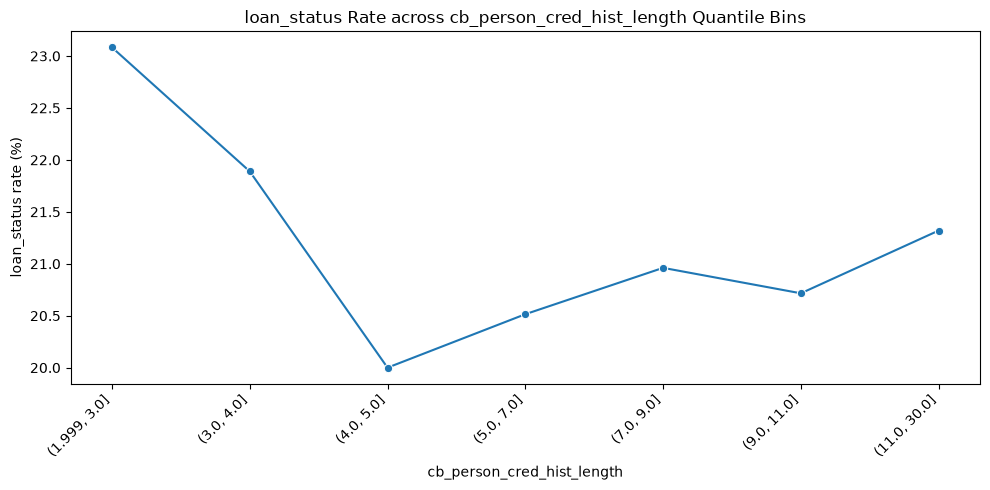

In [10]:
for feature in ["person_age", "person_income", "loan_amnt", "loan_percent_income", "cb_person_cred_hist_length"]:
    print("\n", feature)
    display(numeric_target_rate_by_quantile(train, feature, TARGET, bins=10))
    plot_numeric_target_rate(train, feature, TARGET, bins=10)